# Task 1: Data Cleaning and Preprocessing
**Dataset:** Churn prediction data (churn-bigml-20.csv)
**Goal:** Clean the data so it is ready for analysis.
## Step 1: Load the data
First, I import pandas and load the CSV file into a table called df.
loading data from the churn-bigml-20.csv file

In [1]:
import pandas as pd

df = pd.read_csv("churn-bigml-20.csv")
df.head()

,State,Account length,Area code,International plan,Voice mail plan,Number vmail messages,Total day minutes,Total day calls,Total day charge,Total eve minutes,Total eve calls,Total eve charge,Total night minutes,Total night calls,Total night charge,Total intl minutes,Total intl calls,Total intl charge,Customer service calls,Churn
0,LA,117,408,No,No,0,184.5,97,31.37,351.6,80,29.89,215.8,90,9.71,8.7,4,2.35,1,False
1,IN,65,415,No,No,0,129.1,137,21.95,228.5,83,19.42,208.8,111,9.40,12.7,6,3.43,4,True
2,NY,161,415,No,No,0,332.9,67,56.59,317.8,97,27.01,160.6,128,7.23,5.4,9,1.46,4,True
3,SC,111,415,No,No,0,110.4,103,18.77,137.3,102,11.67,189.6,105,8.53,7.7,6,2.08,2,False
4,HI,49,510,No,No,0,119.3,117,20.28,215.1,109,18.28,178.7,90,8.04,11.1,1,3.00,1,False


## step 2: look at the data we have.
the df.shape() gives the rows and columns we have in the dataset or the size of the table
df.info() shows the summery of every column.

In [2]:
print(df.shape)
df.info()

(667, 20)
<class 'pandas.DataFrame'>
RangeIndex: 667 entries, 0 to 666
Data columns (total 20 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   State                   667 non-null    str    
 1   Account length          667 non-null    int64  
 2   Area code               667 non-null    int64  
 3   International plan      667 non-null    str    
 4   Voice mail plan         667 non-null    str    
 5   Number vmail messages   667 non-null    int64  
 6   Total day minutes       667 non-null    float64
 7   Total day calls         667 non-null    int64  
 8   Total day charge        667 non-null    float64
 9   Total eve minutes       667 non-null    float64
 10  Total eve calls         667 non-null    int64  
 11  Total eve charge        667 non-null    float64
 12  Total night minutes     667 non-null    float64
 13  Total night calls       667 non-null    int64  
 14  Total night charge      667 non-null    flo



## Step 3: Check for missing values
Missing values can cause problems later, so I count how many empty cells are in each column.
since i have a 0 for the df.isnull().sum() meaning i have no missing values.
then we had to check for the duplicates in the data set we have.


In [3]:
df.isnull().sum()

State                     0
Account length            0
Area code                 0
International plan        0
Voice mail plan           0
Number vmail messages     0
Total day minutes         0
Total day calls           0
Total day charge          0
Total eve minutes         0
Total eve calls           0
Total eve charge          0
Total night minutes       0
Total night calls         0
Total night charge        0
Total intl minutes        0
Total intl calls          0
Total intl charge         0
Customer service calls    0
Churn                     0
dtype: int64

since we have no duplicates and missing values so no cells were replaced 

## Step 4: Remove duplicate rows
Duplicate rows can make the results wrong. I count them first, then remove them.
print("Duplicate rows:", df.duplicated().sum())
df = df.drop_duplicates()
print("Rows now:", df.shape[0])
using the code above i had to check for duplicates and then remove them if at all they exist and i had to count the 
number of rows i have left those without duplicates.


In [4]:
print("Duplicate rows:", df.duplicated().sum())
df=df.drop_duplicates()
print("Rows now:", df.shape[0])

Duplicate rows: 0
Rows now: 667


## Step 5: Clean the column names
I make all column names lowercase and replace spaces with underscores. This makes them easier to type
and easier to work with.

In [5]:
df.columns = df.columns.str.strip().str.lower().str.replace(' ', '_')
df.columns

Index(['state', 'account_length', 'area_code', 'international_plan',
       'voice_mail_plan', 'number_vmail_messages', 'total_day_minutes',
       'total_day_calls', 'total_day_charge', 'total_eve_minutes',
       'total_eve_calls', 'total_eve_charge', 'total_night_minutes',
       'total_night_calls', 'total_night_charge', 'total_intl_minutes',
       'total_intl_calls', 'total_intl_charge', 'customer_service_calls',
       'churn'],
      dtype='str')

The plan columns and churn were already numbers, so no conversion was needed.

## Step 6: Check the data types
I check that each column has the right data type. The churn column is True/False, so I change it to 1 and 0.
to make it more like what the computer understands which is binary 1s and 0s.

In [6]:
print(df.dtypes)
df["churn"] = df["churn"].astype("int")
df["churn"].value_counts()

state                         str
account_length              int64
area_code                   int64
international_plan            str
voice_mail_plan               str
number_vmail_messages       int64
total_day_minutes         float64
total_day_calls             int64
total_day_charge          float64
total_eve_minutes         float64
total_eve_calls             int64
total_eve_charge          float64
total_night_minutes       float64
total_night_calls           int64
total_night_charge        float64
total_intl_minutes        float64
total_intl_calls            int64
total_intl_charge         float64
customer_service_calls      int64
churn                        bool
dtype: object


churn
0    572
1     95
Name: count, dtype: int64

## Step 7: Look at the numbers
I look at the minimum, maximum and average of each number column to see if anything looks wrong, like negative values.

In [7]:
df.describe()

,account_length,area_code,number_vmail_messages,total_day_minutes,total_day_calls,total_day_charge,total_eve_minutes,total_eve_calls,total_eve_charge,total_night_minutes,total_night_calls,total_night_charge,total_intl_minutes,total_intl_calls,total_intl_charge,customer_service_calls,churn
count,667.000000,667.000000,667.000000,667.000000,667.000000,667.000000,667.000000,667.000000,667.000000,667.000000,667.000000,667.000000,667.000000,667.000000,667.000000,667.000000,667.000000
mean,102.841079,436.157421,8.407796,180.948126,100.937031,30.761769,203.355322,100.476762,17.285262,199.685307,100.113943,8.985907,10.238381,4.527736,2.764948,1.563718,0.142429
std,40.819480,41.783305,13.994480,55.508628,20.396790,9.436463,49.719268,18.948262,4.226160,49.759931,20.172505,2.239429,2.807850,2.482442,0.758167,1.333357,0.349752
min,1.000000,408.000000,0.000000,25.900000,30.000000,4.400000,48.100000,37.000000,4.090000,23.200000,42.000000,1.040000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,76.000000,408.000000,0.000000,146.250000,87.500000,24.860000,171.050000,88.000000,14.540000,167.950000,86.000000,7.560000,8.600000,3.000000,2.320000,1.000000,0.000000
50%,102.000000,415.000000,0.000000,178.300000,101.000000,30.310000,203.700000,101.000000,17.310000,201.600000,100.000000,9.070000,10.500000,4.000000,2.840000,1.000000,0.000000
75%,128.000000,415.000000,20.000000,220.700000,115.000000,37.520000,236.450000,113.000000,20.095000,231.500000,113.500000,10.420000,12.050000,6.000000,3.255000,2.000000,0.000000
max,232.000000,510.000000,51.000000,334.300000,165.000000,56.830000,361.800000,168.000000,30.750000,367.700000,175.000000,16.550000,18.300000,18.000000,4.940000,8.000000,1.000000


## Step 8: Check for outliers
Outliers are values that are far from the rest. I use a box plot to see them, then count them.
imported libraries that help in data visualization.

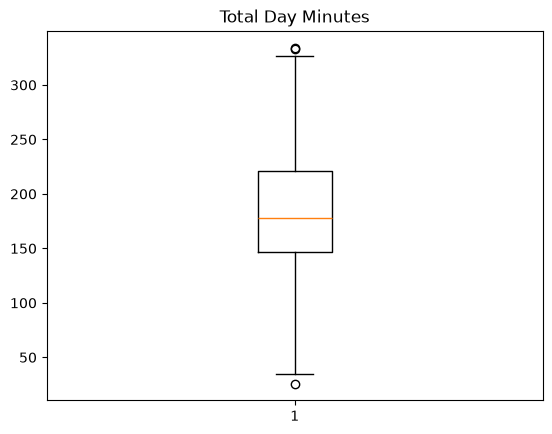

In [8]:
import matplotlib.pyplot as plt
plt.boxplot(df['total_day_minutes'])
plt.title("Total Day Minutes")
plt.show()


this code counts the number of outliers
These outliers look like real customers who talk a lot, so I decided to keep them.

In [9]:
Q1 = df["total_day_minutes"].quantile(0.25)
Q3 = df["total_day_minutes"].quantile(0.75)
IQR = Q3 - Q1

outliers = df[(df["total_day_minutes"] < Q1 - 1.5 * IQR) |
              (df["total_day_minutes"] > Q3 + 1.5 * IQR)]
print("Number of outliers:", len(outliers))

Number of outliers: 3


## Step 9: Change Yes/No columns to numbers
Models work with numbers, so I change Yes to 1 and No to 0.
for easy reading 

In [10]:
print(df["international_plan"].unique())
print(df["voice_mail_plan"].unique())
df["international_plan"] = df["international_plan"].map({"Yes": 1, "No": 0})
df["voice_mail_plan"] = df["voice_mail_plan"].map({"Yes": 1, "No": 0})
df[["international_plan", "voice_mail_plan"]].head()

<StringArray>
['No', 'Yes']
Length: 2, dtype: str
<StringArray>
['No', 'Yes']
Length: 2, dtype: str


,international_plan,voice_mail_plan
0,0,0
1,0,0
2,0,0
3,0,0
4,0,0


## Step 10: Change the state column to numbers
The state column is text with many different values. I turn each state into its own 0/1 column.

In [11]:
df = pd.get_dummies(df, columns=["state"], drop_first=True)
df.shape

(667, 69)

## Step 11: Scale the number columns
Some columns have big numbers and some have small ones. Scaling puts them on the same level so no column dominates.

In [12]:
from sklearn.preprocessing import StandardScaler

num_cols = ["account_length", "total_day_minutes", "total_eve_minutes",
            "total_night_minutes", "total_intl_minutes", "customer_service_calls"]

df[num_cols] = StandardScaler().fit_transform(df[num_cols])
df[num_cols].head()

,account_length,total_day_minutes,total_eve_minutes,total_night_minutes,total_intl_minutes,customer_service_calls
0,0.347127,0.064036,2.983872,0.324092,-0.548297,-0.423098
1,-0.927731,-0.934756,0.506113,0.183311,0.877350,1.828550
2,1.425853,2.739500,2.303545,-0.786067,-1.724455,1.828550
3,0.200028,-1.271894,-1.329563,-0.202831,-0.904709,0.327451
4,-1.319994,-1.111438,0.236397,-0.422048,0.307091,-0.423098


## Step 12: Save the clean data
I save the cleaned table as a new CSV file.

In [13]:
df.to_csv("cleaned_churn_data-20.csv", index=False)
print("Saved!", df.shape)

Saved! (667, 69)


## Summary
- The data has 667 rows and [number] columns.
- There were no missing values.
- There were no duplicate rows.
- The column names were already clean.
- Churn and the plan columns were already numbers.
- I checked outliers and kept them, because they look like real customers.
- I turned the state column into 0/1 columns.
- I scaled the number columns.
- I saved the clean data as cleaned_churn_data-20.csv.